In [54]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from datasets import load_dataset

#Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Cleaning the date and skills columns
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [55]:
# Defining countries that we will filter with
mena_countries = ['Sudan','Egypt', 'Kuwait', 'Saudi Arabia', 'Jordan', 'United Arab Emirates', 'Lebanon', 'Libya', 'Syria', 'Qatar', 'Iraq',
                   'Morocco', 'Palestine', 'Algeria', 'Tunisia', 'Bahrain', 'Oman', 'Yemen'  ]

# Filtering for only data analyst job postings
df_mena_DA = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short']=='Data Analyst') & (df['job_skills'].notna())
                & (df['salary_year_avg'].notna())]

In [56]:
df_mena_DA_exploded = df_mena_DA.explode('job_skills')

df_DA_skills = df_mena_DA_exploded.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by = 'count', ascending= False)

DA_total_job_count = len(df_mena_DA)

df_DA_skills = df_DA_skills.rename(columns={'count': 'skill_count', 'median':'median_salary'})

df_DA_skills['skills_percentage'] = df_DA_skills['skill_count'] / DA_total_job_count * 100


In [57]:
skill_percent = 5
df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skills_percentage'] > skill_percent]
df_DA_skills_high_demand['skills_percentage']


job_skills
sql           56.198347
excel         40.495868
python        34.710744
tableau       30.578512
power bi      22.314050
r             22.314050
oracle        14.049587
sas           13.223140
word          12.396694
azure         11.570248
mongodb        8.264463
sql server     8.264463
terminal       7.438017
snowflake      6.611570
flow           6.611570
powerpoint     6.611570
javascript     5.785124
linux          5.785124
matlab         5.785124
aws            5.785124
sap            5.785124
Name: skills_percentage, dtype: float64

<Figure size 900x1400 with 0 Axes>

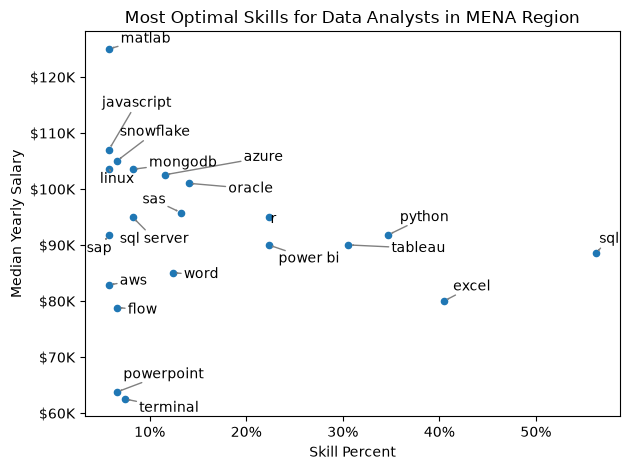

<Figure size 900x1400 with 0 Axes>

In [58]:
from adjustText import adjust_text

df_DA_skills_high_demand.plot(kind = 'scatter', x= 'skills_percentage', y= 'median_salary')
texts = []

for i,text in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skills_percentage'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i],text))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos : f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos : f'{int(y)}%'))


adjust_text(texts, expand=(1.4, 1.8), arrowprops=dict(arrowstyle='->', color='gray'))

plt.xlabel('Skill Percent')
plt.ylabel('Median Yearly Salary')
plt.title(f'Most Optimal Skills for Data Analysts in MENA Region')
plt.tight_layout()
plt.figure(figsize=(9,14))

In [59]:
df_technology = df['job_type_skills'].copy()

df_technology = df_technology.dropna()

df_technology = df_technology.drop_duplicates()


In [60]:
technology_dict = {}

for row in df_technology:
    cleaned_row = ast.literal_eval(row)
    for key, value in cleaned_row.items():
        if key in technology_dict:
            technology_dict[key] += value
        else:
            technology_dict[key] = value
for key,value in technology_dict.items():
    technology_dict[key] = list(set(value))


In [61]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns= ['technology','skills'])
df_technology = df_technology.explode('skills')

In [64]:
df_plot = df_DA_skills_high_demand.merge(df_technology, left_on= 'job_skills', right_on= 'skills')

,skill_count,median_salary,skills_percentage,technology,skills
0,68,88500.00,56.198347,programming,sql
1,49,80000.00,40.495868,analyst_tools,excel
2,42,91800.00,34.710744,programming,python
3,37,90000.00,30.578512,analyst_tools,tableau
4,27,90000.00,22.314050,analyst_tools,power bi
5,27,95000.00,22.314050,programming,r
6,17,101000.00,14.049587,cloud,oracle
7,16,95782.00,13.223140,analyst_tools,sas
8,16,95782.00,13.223140,programming,sas
9,15,85000.00,12.396694,analyst_tools,word


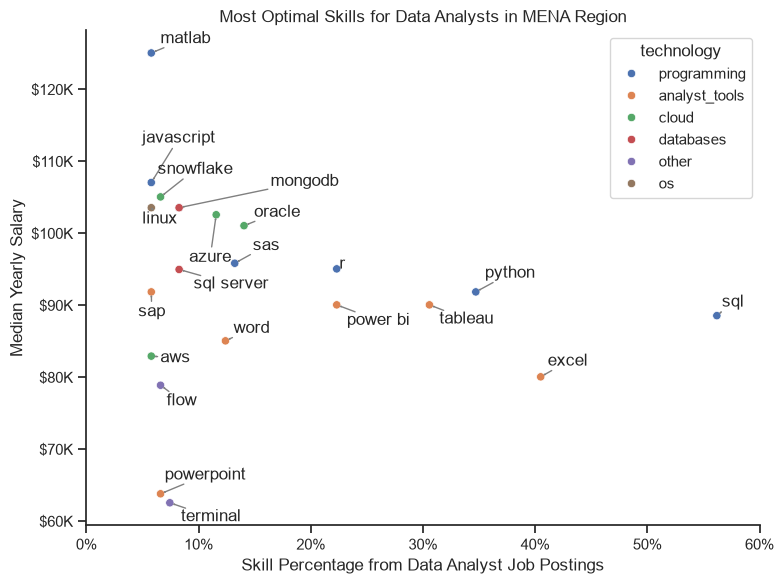

In [83]:
from adjustText import adjust_text

plt.figure(figsize=(8,6))
sns.set_theme(style= 'ticks')

# df_plot.plot(kind = 'scatter', x= 'skills_percentage', y= 'median_salary')
sns.scatterplot(
    data = df_plot,
    x = 'skills_percentage',
    y = 'median_salary',
    hue = 'technology'
)

sns.despine()

texts = []

for i,text in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skills_percentage'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i],text))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos : f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos : f'{int(y)}%'))


adjust_text(texts, expand=(1.4, 1.8), arrowprops=dict(arrowstyle='->', color='gray'))

plt.xlim(0,60)
plt.xlabel('Skill Percentage from Data Analyst Job Postings')
plt.ylabel('Median Yearly Salary')
plt.title(f'Most Optimal Skills for Data Analysts in MENA Region')
plt.tight_layout()


In [84]:
df_mena_DA

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
2390,Data Analyst,Data Analyst,"Midland, TX",via Indeed,Full-time,False,Sudan,2023-08-25 13:40:40,False,True,Sudan,year,70000.0,NaN,"Advanced Stimulation Technologies, Inc","[c, outlook, word, excel, powerpoint]","{'analyst_tools': ['outlook', 'word', 'excel',..."
4709,Data Analyst,Data Analyst,Anywhere,via LinkedIn,Full-time,True,Sudan,2023-10-09 13:40:58,False,False,Sudan,year,77500.0,NaN,Simplex.,"[python, sql, sqlite, snowflake, azure]","{'cloud': ['snowflake', 'azure'], 'databases':..."
9448,Data Analyst,Marketing Data Analyst,"Dallas, TX",via Ai-Jobs.net,Full-time,False,Sudan,2023-08-17 13:38:18,False,False,Sudan,year,90000.0,NaN,OrderMyGear,"[sql, looker, excel, tableau, power bi]","{'analyst_tools': ['looker', 'excel', 'tableau..."
13750,Data Analyst,Data Conversion Analyst,Anywhere,via LinkedIn,Full-time,True,Sudan,2023-06-23 14:21:18,False,False,Sudan,year,100000.0,NaN,Insight Global,[power bi],{'analyst_tools': ['power bi']}
35631,Data Analyst,Data Analyst must have telecom domain experince,Anywhere,via LinkedIn,Contractor,True,Sudan,2023-04-28 13:56:12,True,False,Sudan,year,130000.0,NaN,ApTask,"[sql, python, sheets, flow]","{'analyst_tools': ['sheets'], 'other': ['flow'..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756334,Data Analyst,Data Analyst,Anywhere,via LinkedIn,Full-time,True,Sudan,2023-08-08 20:49:34,False,True,Sudan,year,72500.0,NaN,Bluesight,"[sql, python, r, ruby, ruby, excel, sheets]","{'analyst_tools': ['excel', 'sheets'], 'progra..."
764620,Data Analyst,Data Analyst,Anywhere,via LinkedIn,Full-time,True,Sudan,2023-04-28 20:56:12,True,False,Sudan,year,87500.0,NaN,Insight Global,"[sql, c#, sql server, excel, flow]","{'analyst_tools': ['excel'], 'databases': ['sq..."
768494,Data Analyst,"Data Analyst / Data Scientist, Wholesale","Dallas, TX",via Talentify,Full-time,False,Sudan,2023-06-29 02:26:06,False,False,Sudan,year,118965.0,NaN,Frontier Communications,"[python, pandas, excel, alteryx]","{'analyst_tools': ['excel', 'alteryx'], 'libra..."
771454,Data Analyst,Data Analyst,United States,via Ai-Jobs.net,Full-time,False,Sudan,2023-06-21 02:00:05,False,False,Sudan,year,100500.0,NaN,Govini,"[python, r]","{'programming': ['python', 'r']}"
